In [1]:
import sys
sys.path.append('..')
import logging
logging.basicConfig(level=logging.WARN)

Initial score:  0.0006870208546553084
New score:  0.0009869897338460267
New action:  (ComputeModule_0_0_49_49, Grid, X, 7)
New score:  0.0010290601962064023
New action:  (ComputeModule_24_0_30_6, Radial, Y, 1)
Package score:  0.0009358280623158449


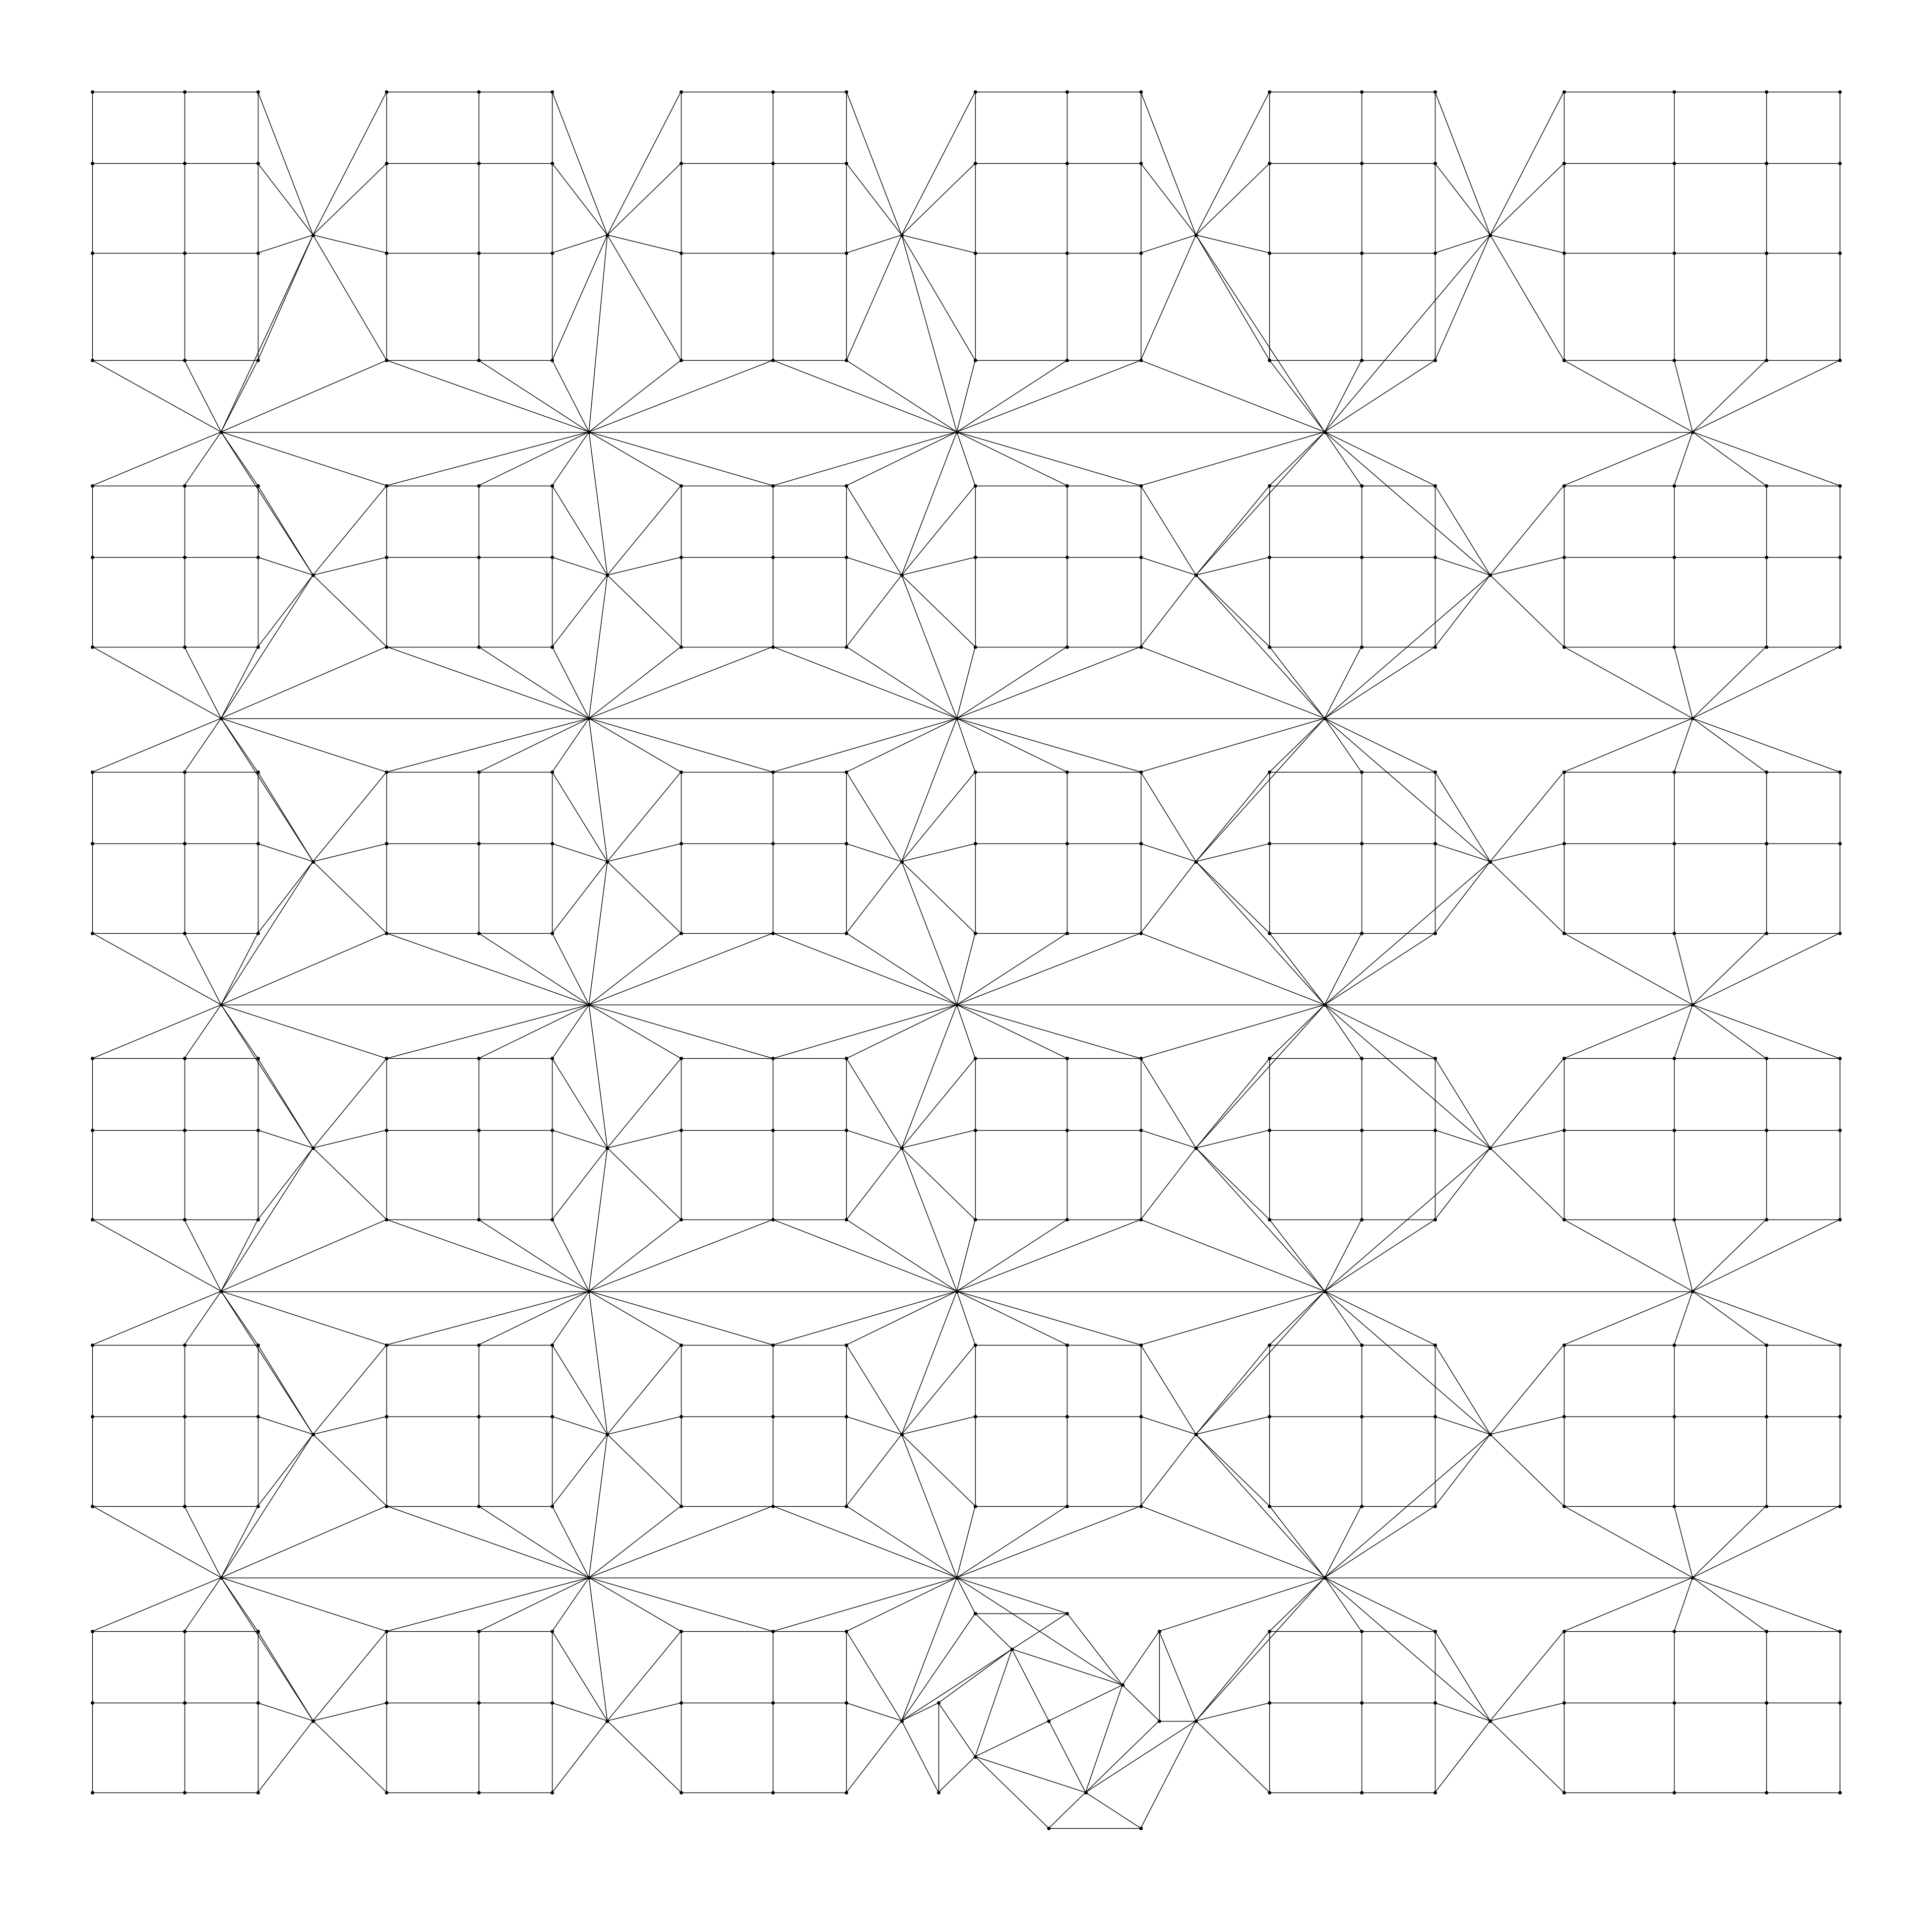

In [2]:
from qunoc.element.package import *

# package = Package(design_strategy="greedy")
fabricate_model = FabricateModel(10, 10)
package = Package((50, 50), fabricate_model, design_strategy="greedy")

print("Package score: ", package.estimate_efficiency())
package.draw_chiplets()

In [2]:
from qunoc.element.benchmark import *

vqe_program = VQE(5)
print(f"VQE program: {vqe_program}")
qft_program = QFT(5)
print(f"QFT program: {qft_program}")
qaoa_program = QAOA(5)
print(f"QAOA program: {qaoa_program}")
bv_program = BV(5)
print(f"BV program: {bv_program}")

VQE program: Control_0_1, Control_0_2, Control_0_3, Control_0_4, Control_1_2, Control_1_3, Control_1_4, Control_2_3, Control_2_4, Control_3_4
QFT program: Control_1_0, Control_2_0, Control_3_0, Control_2_1, Control_4_0, Control_3_1, Control_4_1, Control_3_2, Control_4_2, Control_4_3
QAOA program: Control_0_1, Control_0_2, Control_0_4, Control_2_3, Control_0_3
BV program: Control_0_2, Control_0_3


In [ ]:
from qunoc.layout.env import QuantumChipletEnv
from qunoc.layout.agent import LayoutAgent
# from gymnasium.wrappers import Monitor

env = QuantumChipletEnv(package_size=(22, 11))
# env = Monitor(env, "./logs")
agent = LayoutAgent(env)

agent.train(total_timesteps=50000)
agent.save("ppo_quantum_chip_agent.zip")

print("Testing agent...")
state = env.reset()
for _ in range(1000):
    actions = agent.select_action(state)
    print("Selected Actions:", actions)
    state, reward, done, _ = env.step(actions)
    print(env.estimate())
    if done:
        break